# Spotify Tracks Data Analysis 🎵
##### This dataset contains information about music tracks, including artists, genres, album types, release years, popularity, streaming counts, and playlist presence. It also includes audio features such as danceability, energy, loudness, acousticness, valence, and tempo.

##### The goal of this analysis is to explore music trends, identify the most popular and streamed tracks, compare genres, and investigate the relationship between audio features and track popularity.

### 1. Import Needed Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.subplots as make_subplots

### 2 Reviewing & Understanding Data

In [5]:
df=pd.read_excel('spotify_data_10k.xlsx')
df.head()

,track_id,track_name,artist_name,genre,album_type,release_year,popularity,duration_ms,danceability,energy,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,explicit,stream_count,in_playlists,language
0,track_00001,Song 1,Queen,NaN,single,1983,18.0,201998.500112,0.651979,0.808438,...,0.212422,0.505556,0.211911,0.608544,107.080427,4,0.0,7.068590e+07,11.0,Arabic
1,track_00002,Song 2,Bad Bunny,Country,album,2012,66.0,147130.548023,0.549080,0.604588,...,NaN,0.479801,0.545568,0.700135,126.399233,4,0.0,4.229579e+05,16.0,English
2,track_00003,Song 3,Bruno Mars,EDM,album,2023,97.0,186752.376391,0.564957,0.760707,...,0.134327,0.420292,0.179326,0.686540,104.818212,4,0.0,7.989312e+07,13.0,Spanish
3,track_00004,Song 4,BTS,R&B,compilation,2017,82.0,229882.135212,0.883808,0.209222,...,0.066239,0.941878,0.714081,0.722659,131.862504,4,1.0,5.867061e+06,NaN,Spanish
4,track_00005,Song 5,Travis Scott,Pop,single,1996,95.0,193433.264985,0.152025,0.163799,...,0.362427,0.449509,0.658111,0.884495,108.676874,4,1.0,3.288462e+07,8.0,English


In [6]:
df.columns

Index(['track_id', 'track_name', 'artist_name', 'genre', 'album_type',
       'release_year', 'popularity', 'duration_ms', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'explicit', 'stream_count', 'in_playlists', 'language'],
      dtype='str')

In [7]:
df.shape

(10000, 24)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  str    
 1   track_name        10000 non-null  str    
 2   artist_name       9423 non-null   str    
 3   genre             8862 non-null   str    
 4   album_type        9531 non-null   str    
 5   release_year      10000 non-null  int64  
 6   popularity        8946 non-null   float64
 7   duration_ms       10000 non-null  float64
 8   danceability      8901 non-null   float64
 9   energy            9355 non-null   float64
 10  key               8787 non-null   float64
 11  loudness          9199 non-null   float64
 12  mode              10000 non-null  int64  
 13  speechiness       9598 non-null   float64
 14  acousticness      9314 non-null   float64
 15  instrumentalness  10000 non-null  float64
 16  liveness          10000 non-null  float64
 17  valen

In [9]:
df.describe()

,release_year,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,explicit,stream_count,in_playlists
count,10000.000000,8946.000000,1.000000e+04,8901.000000,9355.000000,8787.00000,9199.000000,10000.000000,9598.000000,9314.000000,10000.000000,10000.000000,10000.000000,9107.000000,10000.000000,9109.000000,1.000000e+04,8867.000000
mean,1991.983600,52.454281,2.298537e+05,0.582090,0.522212,5.03619,-17.133189,0.653200,0.359705,0.494972,0.472969,0.496268,0.500204,121.682925,3.949800,0.213306,2.742023e+08,14.894327
std,18.908884,58.068797,4.675943e+05,0.831244,0.268877,3.73390,39.414734,0.475975,0.195790,0.286030,0.273828,0.259300,0.283209,45.283821,0.381437,0.409664,5.803713e+09,4.950625
min,1960.000000,0.000000,-9.999900e+04,0.100007,0.050122,-1.00000,-800.000000,0.000000,0.020156,0.000350,0.000178,0.050002,0.010102,0.000000,3.000000,0.000000,-5.000000e+06,-50.000000
25%,1976.000000,24.000000,1.788551e+05,0.324203,0.290173,2.00000,-23.009402,0.000000,0.190211,0.244265,0.235820,0.272356,0.256211,101.586054,4.000000,0.000000,1.389214e+07,12.000000
50%,1992.000000,50.000000,2.099845e+05,0.541019,0.522159,5.00000,-15.970148,1.000000,0.360154,0.500095,0.468062,0.494273,0.496562,120.341248,4.000000,0.000000,3.381432e+07,15.000000
75%,2009.000000,76.000000,2.406954e+05,0.762822,0.756941,8.00000,-9.071305,1.000000,0.526940,0.741659,0.707261,0.718110,0.747954,138.866990,4.000000,0.000000,6.913722e+07,18.000000
max,2024.000000,999.000000,1.441602e+07,15.500000,0.989883,11.00000,250.000000,1.000000,0.699944,0.989313,0.949921,0.949942,0.989767,999.000000,5.000000,1.000000,1.500000e+11,35.000000


In [10]:
df.describe(include='object')

C:\Users\SA\AppData\Local\Temp\ipykernel_18348\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,track_id,track_name,artist_name,genre,album_type,language
count,10000,10000,9423,8862,9531,9188
unique,10000,10000,24,11,3,12
top,track_00001,Song 1,Justin Bieber,Pop,album,English
freq,1,1,428,1808,4858,4037


### 3.Cleaning Data

#### 3.1 Check missing values & duplicates

In [11]:
# Missing values
df.isnull().sum()

track_id               0
track_name             0
artist_name          577
genre               1138
album_type           469
release_year           0
popularity          1054
duration_ms            0
danceability        1099
energy               645
key                 1213
loudness             801
mode                   0
speechiness          402
acousticness         686
instrumentalness       0
liveness               0
valence                0
tempo                893
time_signature         0
explicit             891
stream_count           0
in_playlists        1133
language             812
dtype: int64

In [12]:
#Duplicated Values
df.duplicated().sum()

np.int64(0)

#### 3.2 Handle Missing Values

In [13]:
#Handle missing values in numerical data
numerical_cols = df.select_dtypes(include='number').columns
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].mean())

In [14]:
# Handle missing values in categorical data
categorical_cols = df.select_dtypes(exclude='number').columns
df[categorical_cols] = df[categorical_cols].fillna(df[categorical_cols].mode().iloc[0])

In [15]:
df.isnull().sum()

track_id            0
track_name          0
artist_name         0
genre               0
album_type          0
release_year        0
popularity          0
duration_ms         0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
explicit            0
stream_count        0
in_playlists        0
language            0
dtype: int64

#### 3.3 Handle Outliers

In [16]:
for col in df.select_dtypes(include=['number']).columns:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    IQR=q3-q1
    LB=q1-1.5*IQR
    UB=q3+1.5*IQR
    df[col]=df[col].clip(lower=LB,upper=UB)
    outliers=df[(df[col]<LB)|(df[col]>UB)]

In [17]:
outliers

,track_id,track_name,artist_name,genre,album_type,release_year,popularity,duration_ms,danceability,energy,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,explicit,stream_count,in_playlists,language


### 4. EDA(Exploratory Data Analysis)

In [18]:
df.columns

Index(['track_id', 'track_name', 'artist_name', 'genre', 'album_type',
       'release_year', 'popularity', 'duration_ms', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'explicit', 'stream_count', 'in_playlists', 'language'],
      dtype='str')

In [19]:
#KPI1(Total Tracks)
Total_Tracks=df['track_id'].count()
Total_Tracks

np.int64(10000)

In [20]:
KPI1=go.Indicator(
    mode='number',
    value=Total_Tracks,
    title={'text':'Total Tracks'}
)

In [21]:
#KPI2(Total Streams)
Total_Streams=round(df['stream_count'].sum())
Total_Streams

471587293791

In [22]:
KPI2=go.Indicator(
    mode='number',
    value=Total_Streams,
    title={'text':'Total Streams'}
)

In [23]:
#KPI3(Average Popularity)
Average_Popularity=round(df['popularity'].mean())
Average_Popularity

50

In [24]:
KPI3=go.Indicator(
    mode='number',
    value=Average_Popularity,
    title={'text':'Average Popularity'}
)

##### Chart 1 — Distribution of Track Popularity

In [25]:
df['popularity'].describe()

count    10000.000000
mean        50.311781
std         28.140785
min          0.000000
25%         27.000000
50%         52.454281
75%         73.000000
max        142.000000
Name: popularity, dtype: float64

In [26]:
fig1 = px.histogram(data_frame=df,x='popularity',nbins=40,color_discrete_sequence=['blue'],title='Distribution of popularity',opacity=0.9,template='plotly_dark')
fig1.update_layout(xaxis_title='Popularity',yaxis_title='Number of Tracks',bargap=0.1,xaxis=dict(tickmode='linear',tick0=0,dtick=10),title_x=0.5)
fig1.show()

##### Chart 2 — Top 10 Genres by Total Streams

In [27]:
genre_streams = (
    df.groupby('genre', as_index=False)['stream_count']
      .sum()
      .nlargest(10, 'stream_count')
      .sort_values('stream_count')
)

fig2 = px.bar(
    genre_streams,
    x='stream_count',
    y='genre',
    orientation='h',
    title='Top 10 Genres by Total Streams',
    labels={
        'stream_count': 'Total Streams',
        'genre': 'Genre'
    },
    template='plotly_dark'
)

fig2.show()

##### Chart 3 — Donut Chart: Tracks by Album Type

In [28]:
album_counts = df['album_type'].value_counts().reset_index()
album_counts.columns = ['album_type', 'track_count']

fig3 = px.pie(
    album_counts,
    names='album_type',
    values='track_count',
    hole=0.5,
    title='Track Distribution by Album Type',
    template='plotly_dark'
)

fig3.update_traces(
    textinfo='percent+label',
    textposition='inside'
)
fig3.update_layout(title_x=0.5)

fig3.show()

##### Chart 4 — Danceability vs Energy

In [29]:
fig4 = px.scatter(
    df,
    x='danceability',
    y='energy',
    color='popularity',
    hover_data=['track_name', 'artist_name', 'genre'],
    title='Danceability vs Energy by Track Popularity',
    color_continuous_scale='Viridis',
    template='plotly_dark',
    opacity=0.7
)
fig4.update_layout(title_x=0.5)

fig4.show()

##### Chart 5 — Pie Chart: Explicit vs Non-Explicit Tracks

In [43]:
explicit_counts = df['explicit'].value_counts().reset_index()
explicit_counts.columns = ['explicit', 'track_count']
explicit_counts['explicit'] = explicit_counts['explicit'].map({
    True: 'Explicit',
    False: 'Non-Explicit',
    1: 'Explicit',
    0: 'Non-Explicit'
}).fillna(explicit_counts['explicit'].astype(str))
fig5 = px.pie(
    explicit_counts,
    names='explicit',
    values='track_count',
    title='Explicit vs Non-Explicit Tracks',
    template='plotly_dark'
)

fig5.update_traces(
    textinfo='percent+label',
    textposition='inside',
)
fig5.update_layout(title_x=0.5)

fig5.show()

##### Chart 6 — Bar Chart: Top 10 Artists by Total Streams

In [ ]:
artist_streams = (
    df.groupby('artist_name', as_index=False)['stream_count']
      .sum()
      .nlargest(10, 'stream_count')
      .sort_values('stream_count')
)

fig6 = px.bar(
    artist_streams,
    x='stream_count',
    y='artist_name',
    orientation='h',
    text='stream_count',
    title='Top 10 Artists by Total Streams',
    labels={
        'artist_name': 'Artist',
        'stream_count': 'Total Streams'
    },
    template='plotly_dark'
)

fig6.update_traces(
    textposition='outside',
    cliponaxis=False
)

fig6.update_layout(
    yaxis={'categoryorder': 'total ascending'},title_x=0.5
)

fig6.show()

##### Chart 7 — Average Popularity by Release Year

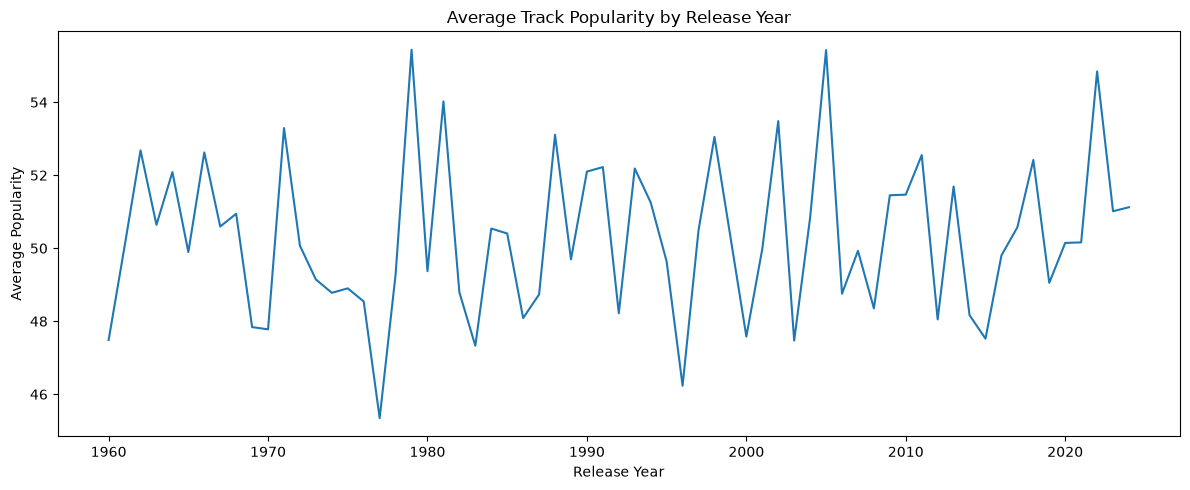

In [ ]:
year_popularity = (
    df.groupby('release_year', as_index=False)
      .agg(
          avg_popularity=('popularity', 'mean'),
          track_count=('track_id', 'nunique')
      )
)

# استبعدت السنوات ذات الأعداد القليلة جدًا
year_popularity = year_popularity[
    year_popularity['track_count'] >= 10
]

plt.figure(figsize=(12, 5))

fig7=sns.lineplot(
    data=year_popularity,
    x='release_year',
    y='avg_popularity',
)

plt.title('Average Track Popularity by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Popularity')
plt.tight_layout()
plt.show()

##### Chart 8 — Correlation Heatmap of Audio Features

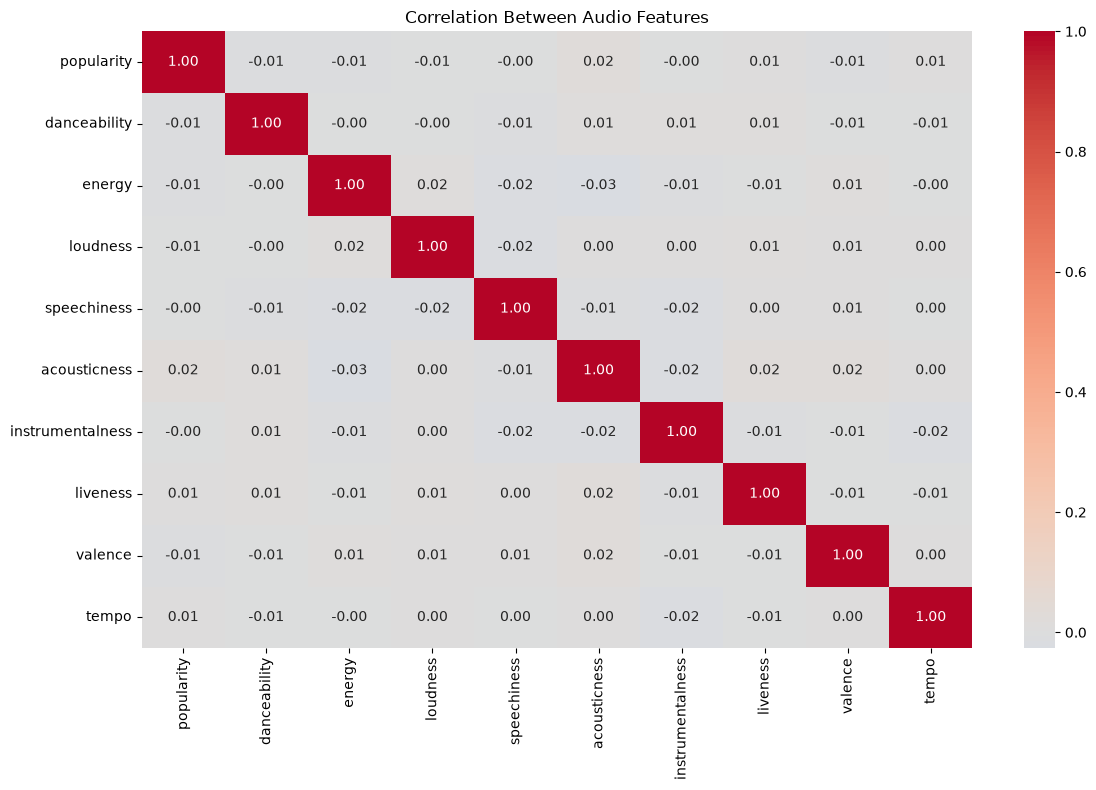

In [ ]:
audio_features = [
    'popularity', 'danceability', 'energy',
    'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo'
]

correlation = df[audio_features].corr()

plt.figure(figsize=(12, 8))

fig8=sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Between Audio Features')
plt.tight_layout()
plt.show()

##### Chart 9 — Explicit vs Non-Explicit Track Popularity

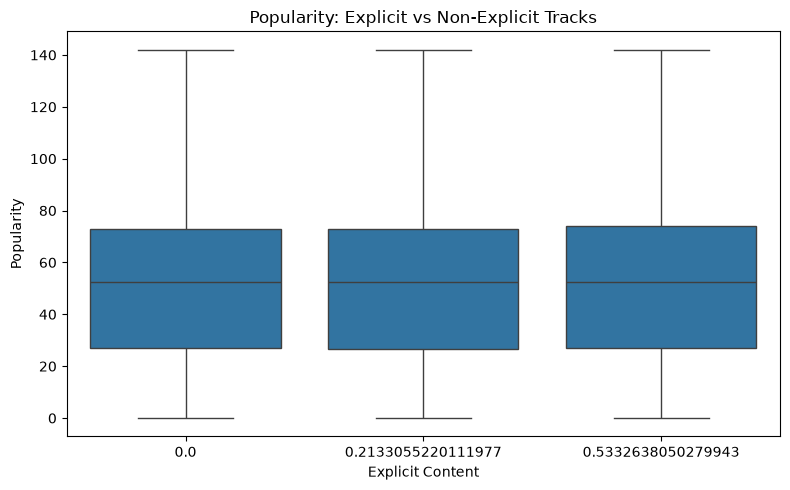

In [ ]:
plt.figure(figsize=(8, 5))

fig9=sns.boxplot(
    data=df,
    x='explicit',
    y='popularity'
)

plt.title('Popularity: Explicit vs Non-Explicit Tracks')
plt.xlabel('Explicit Content')
plt.ylabel('Popularity')
plt.tight_layout()
plt.show()

### Show Dasboard as HTML File

In [ ]:
from plotly.subplots import make_subplots

In [ ]:
fig = make_subplots(
    rows=3,
    cols=3,
    specs=[
        [{"type": "domain"}, {"type": "domain"}, {"type": "domain"}],  # Row 1: 3 KPIs widgets
        [{"type": "xy"}, {"type": "xy"}, {"type": "domain"}],          # Row 2: Charts 1, 2, 3
        [{"type": "xy"}, {"type": "domain"}, {"type": "xy"}]   # Row 3: Charts 4, 5, 6
    ],
    subplot_titles=(
        "", "", "",  # Empty titles for KPI row
        "Distribution of popularity", "Top 10 Genres by Total Streams", "Track Distribution by Album Type",  # Row 2 chart titles
                "Danceability vs Energy by Track Popularity", "Explicit vs Non-Explicit Tracks", "Top 10 Artists by Total Streams"          # Row 3 chart titles
        ),
    vertical_spacing=0.12,
    horizontal_spacing=0.08,
    row_heights=[0.25, 0.37, 0.38]
)

# ==========================================
# 4. Add 3 KPIs to Row 1
# ==========================================
# KPI 1: Total Cars Listed
fig.add_trace(KPI1, row=1, col=1)

# KPI 2: Average Price
fig.add_trace(KPI2, row=1, col=2)

# KPI 3: Average Mileage
fig.add_trace(KPI3, row=1, col=3)


# ==========================================
# 5. Add 6 Charts to Rows 2 & 3
# ==========================================

# Chart 1 (Row 2, Col 1): Bar Chart - Price by Model
for trace in fig1.data:
    fig.add_trace(trace, row=2, col=1)

# Chart 2 (Row 2, Col 2): Line Chart - Price Over Years
for trace in fig2.data:
    fig.add_trace(trace, row=2, col=2)

# Chart 3 (Row 2, Col 3): Scatter Chart - Price vs Mileage
for trace in fig3.data:
    fig.add_trace(trace, row=2, col=3)

# Chart 4 (Row 3, Col 1): Histogram - Horse Power Distribution
for trace in fig4.data:
    fig.add_trace(trace, row=3, col=1)

# Chart 5 (Row 3, Col 2): Pie Chart - Fuel Type Share
for trace in fig5.data:
    fig.add_trace(trace, row=3, col=2)

# Chart 6 (Row 3, Col 3): Donut Chart - Transmission Share
for trace in fig6.data:
    fig.add_trace(trace, row=3, col=3)


# ==========================================
# 6. Apply Final Formatting and Export
# ==========================================
fig.update_layout(
    template='plotly_dark',
    height=1100,
    title_text="Spotify Analytics Dashboard",
    showlegend=False
)

# Display the dashboard interactive fig
fig.update_layout(title_x=0.5)
fig.show()

# Save the final dashboard as an interactive HTML file
fig.write_html('Spotify_Dashboard_3x3.html')

## Conclusion

This project analyzed a dataset of **10,000 Spotify tracks** to explore music trends, streaming performance, popularity, and audio characteristics.

The analysis included data cleaning and exploratory data analysis (EDA), followed by interactive visualizations using Plotly and statistical charts using Matplotlib and Seaborn.

**Key Findings:**
- **Popularity Distribution:** Explored how track popularity is distributed across the dataset, with an average popularity score of approximately 50.
- **Top Genres:** Identified the top 10 music genres based on total streams.
- **Album Types:** Compared the distribution of tracks across albums, singles, and compilations.
- **Audio Features:** Investigated the relationship between danceability and energy, using popularity to distinguish tracks.
- **Artists Performance:** Ranked the top 10 artists by total streams.
- **Music Trends:** Analyzed average track popularity across release years.
- **Explicit Content:** Compared explicit and non-explicit tracks and examined differences in their popularity.
- **Correlation Analysis:** Used a correlation heatmap to explore relationships between audio features.

**Overall Conclusion:**

This project demonstrates how data analysis and visualization can transform raw music data into meaningful insights. It highlights the importance of exploring streaming performance, popularity, and audio characteristics to better understand music trends and listener preferences.

**Tools Used:** Python, Pandas, NumPy, Plotly, Matplotlib, and Seaborn.